In [1]:
print("hello")

hello


In [10]:
from langgraph.graph import StateGraph, START, END
# from langchain_groq import ChatGroq
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
load_dotenv()

True

Generate the blog with the help of topic and it's generated outline from topic itself

In [13]:
# model = ChatGroq(model = 'openai/gpt-oss-120b', temperature = 0)
model = ChatGoogleGenerativeAI(model = "gemini-3.6-flash", temperature = 0)


In [14]:
# define State of graph

class BlogState:
    topic : str
    outline : str
    blog : str

In [15]:
# define the node

def outline(state : BlogState) -> BlogState:
    topic = state['topic']
    prompt = f"Generate one proper and detailed outline from the topic {topic}"

    outline = model.invoke(prompt).content[0]['text']
    state['outline'] = outline
    return state

def blog(state : BlogState) -> BlogState:
    outline = state['outline']
    topic = state['topic']

    prompt = f"Generate the blog using the above topic {topic} and the outline of it {outline}"
    blog = model.invoke(prompt).content[0]['text']
    state['blog'] = blog
    return state

In [16]:
# define the graph and nodes and edges

graph = StateGraph(BlogState)

graph.add_node("outline", outline)
graph.add_node("blog", blog)

graph.add_edge(START, "outline")
graph.add_edge("outline", "blog")
graph.add_edge("blog", END)

workflow = graph.compile()


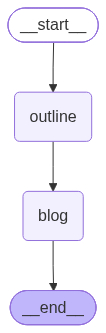

In [17]:
workflow

In [18]:
initial_state = {"topic" : input("Enter your ")}
final_state = workflow.invoke(initial_state)


c:\Users\Admin\Desktop\projects\Agentic AI\venv\Lib\site-packages\langchain_google_genai\chat_models.py:3120: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\Admin\Desktop\projects\Agentic AI\venv\Lib\site-packages\langchain_google_genai\chat_models.py:3120: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


In [19]:
print(final_state)

{'topic': 'DeMonerization in India by PM Modi', 'outline': 'Here is a detailed and structured outline on **Demonetization in India (2016)**.\n\n---\n\n# Comprehensive Outline: Demonetization in India (2016)\n\n## I. Introduction\n   * **A. Definition of Demonetization:** The act of stripping a currency unit of its status as legal tender.\n   * **B. Historical Context in India:**\n     1. Pre-2016 demonetization drives (1946 and 1978).\n     2. Comparison of scale: 2016 affected **86% of the circulating currency** value.\n   * **C. The Announcement:**\n     1. Date: November 8, 2016.\n     2. Mode: National address by Prime Minister Narendra Modi.\n     3. Target Currencies: Invalidation of high-value notes—₹500 and ₹1,000.\n\n## II. Stated Objectives of the Policy\n   * **A. Eradication of Black Money:** Flushing out unaccounted and untaxed cash held in illegal hoards.\n   * **B. Elimination of Counterfeit Currency:** Neutralizing Fake Indian Currency Notes (FICN) in circulation.\n   *

In [21]:
for i in final_state.items():
    print(f"{i[0]} \n {i[1]}")

topic 
 DeMonerization in India by PM Modi
outline 
 Here is a detailed and structured outline on **Demonetization in India (2016)**.

---

# Comprehensive Outline: Demonetization in India (2016)

## I. Introduction
   * **A. Definition of Demonetization:** The act of stripping a currency unit of its status as legal tender.
   * **B. Historical Context in India:**
     1. Pre-2016 demonetization drives (1946 and 1978).
     2. Comparison of scale: 2016 affected **86% of the circulating currency** value.
   * **C. The Announcement:**
     1. Date: November 8, 2016.
     2. Mode: National address by Prime Minister Narendra Modi.
     3. Target Currencies: Invalidation of high-value notes—₹500 and ₹1,000.

## II. Stated Objectives of the Policy
   * **A. Eradication of Black Money:** Flushing out unaccounted and untaxed cash held in illegal hoards.
   * **B. Elimination of Counterfeit Currency:** Neutralizing Fake Indian Currency Notes (FICN) in circulation.
   * **C. Curbing Terror Finan